# 42177 — Cross-Dataset Plant Leaf Disease Classification
## YOLO11s-cls implementation and evaluation
**Wei Cui · Group 2**

In this part of our group project, I implemented YOLO11s-cls to examine how well a model trained on PlantVillage transfers to Cropped PlantDoc. I used the group's shared classes and image manifest so that my predictions can be compared with the other models on the same images. MobileNetV2 was my proposed alternative; I did not train it in this experiment.

This notebook contains my original three-seed experiment with **batch 64** and seeds **42, 43 and 44**. I have kept its measured outputs alongside the code. Later single-seed trials with stronger augmentation are separate exploratory work and are not included here.

For reproduction, I used a Colab T4 runtime and mounted my student Drive. Each new execution creates its own experiment directory. The embedded manifest and source code below reproduce the formal pipeline; the large data archives and official weights are loaded separately.


## 1. Experimental protocol

I kept the shared data split fixed and changed only the training seed between runs. I used PlantVillage validation macro-F1 to select the checkpoint, then evaluated the frozen models on the internal and external test sets.

| Item | Setting I used |
|---|---|
| Classes | The twelve shared plant–disease or healthy labels in the team mapping |
| PlantVillage | 12,174 training, 2,609 validation and 2,609 internal test images |
| Cropped PlantDoc | 1,097 external images from its original train and test folders |
| Data split | The team's stratified 70/15/15 manifest, with split seed 42 |
| Training | Batch 64; two head-only warm-up epochs, then up to twenty full fine-tuning epochs |
| Optimiser | AdamW; head LR 0.001, backbone LR 0.0001; weight decay 0.0001 |
| Schedule | Cosine learning-rate decay during fine-tuning |
| Regularisation | Dropout 0.3, label smoothing 0.1 and training-only augmentation |
| Model selection | Highest PlantVillage validation macro-F1; fine-tuning patience 5 |
| Training seeds | 42, 43 and 44, with the image split unchanged |
| External evaluation | After I fixed all three selected checkpoints and their configurations |

During warm-up, I treated the complete YOLO Classify module, including its final convolution, as the head. I kept the frozen backbone in evaluation mode so its BatchNorm statistics did not change. I used float32 precision on the T4.

My evaluation transform followed the downloaded checkpoint: RGB conversion, shortest-edge resize to 224, centre crop to 224 × 224 and scaling to [0,1]. I used zero mean and unit standard deviation. Teddy's ResNet transform uses resize to 256 and ImageNet normalisation, so the model-specific processing differs even though we use the same image identities and partitions. Centre cropping may remove symptoms near the image edges.

I replaced the original 1,000-class linear output with twelve outputs. Since YOLO's alphabetical class order differs from the team mapping, I converted the predicted indices and probability columns back to the shared order before exporting them.


## 2. Environment and experiment configuration

I recorded the GPU, software versions, batch size and training seeds with each experiment. I saved the results on Drive and used the Colab disk for temporary image caches. The configuration cell also defines the logging helper used by the later steps; it refuses to overwrite an existing log so an accidental rerun cannot erase the evidence from a completed run.


In [1]:
%pip install -q ultralytics==8.4.53 pandas scikit-learn matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 22.1 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
from pathlib import Path
from uuid import uuid4
import os, sys, subprocess, json, hashlib, zipfile, shutil, datetime
import torch, torchvision, ultralytics, numpy as np, pandas as pd
from IPython.display import display, Image as DisplayImage, Markdown

ROOT = Path('/content/drive/MyDrive/42177')
ROOT.mkdir(parents=True, exist_ok=True)
WORK = Path('/content/42177_submission_work')
WORK.mkdir(exist_ok=True)
EXPERIMENT_ID = 'yolo11s_b64_' + datetime.datetime.now(datetime.timezone.utc).strftime('%Y%m%d_%H%M%S') + '_' + uuid4().hex[:8]
RUNS = ROOT / 'runs' / EXPERIMENT_ID
RUNS.mkdir(parents=True, exist_ok=False)
BATCH = 64
SEEDS = [42, 43, 44]
WARMUP_EPOCHS = 2
FINETUNE_EPOCHS = 20
assert torch.cuda.is_available(), 'Select a GPU runtime before running this experiment.'
os.environ['YOLO_CONFIG_DIR'] = str(WORK / 'config')
os.environ['MPLCONFIGDIR'] = str(WORK / 'matplotlib_cache')
(WORK / 'config/Ultralytics').mkdir(parents=True, exist_ok=True)
environment = {'python':sys.version, 'torch':torch.__version__, 'torchvision':torchvision.__version__,
               'ultralytics':ultralytics.__version__, 'gpu':torch.cuda.get_device_name(0),
               'gpu_memory_GiB':torch.cuda.get_device_properties(0).total_memory/2**30,
               'batch':BATCH, 'seeds':SEEDS, 'precision':'float32'}
(RUNS/'notebook_environment.json').write_text(json.dumps(environment,indent=2))
display(pd.Series(environment, name='Value').to_frame())
print('Experiment output:', RUNS)

def run(args, log):
    # Refuse an existing log to preserve evidence when a cell is re-run.
    with Path(log).open('x', buffering=1) as f:
        proc = subprocess.Popen([sys.executable,'-u',*map(str,args)], stdout=subprocess.PIPE,
                                stderr=subprocess.STDOUT, text=True, env=os.environ.copy())
        try:
            for line in proc.stdout:
                print(line,end='');f.write(line)
            if proc.wait()!=0:raise RuntimeError(f'Execution failed. Read {log}')
        except BaseException:
            proc.terminate()
            try:proc.wait(timeout=10)
            except subprocess.TimeoutExpired:proc.kill();proc.wait()
            raise


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


,Value
python,"3.13.15 (main, Aug 6 2026, 11:06:22) [GCC 13...."
torch,2.11.0+cu130
torchvision,0.26.0+cu130
ultralytics,8.4.53
gpu,Tesla T4
gpu_memory_GiB,14.563171
batch,64
seeds,"[42, 43, 44]"
precision,float32


Experiment output: /content/drive/MyDrive/42177/runs/yolo11s_b64_20261018_081158_1afe1516


## 3. Shared manifest and implementation

I reused the original team manifest and class mapping from Teddy's repository, commit `62aa3152d993bffcdf87b4ace9a0e9233705b8e7`. I embedded these files and the complete implementation in this notebook so that the submitted code does not depend on a separate private script folder.

The manifest is compressed to keep the notebook smaller. I restore it locally and verify its SHA256 before loading it. This step restores the agreed image list; it does not create a new split.


In [4]:
#@title Restore the embedded team manifest (compressed only to reduce notebook size)
import gzip, base64
MANIFEST_DATA = '...'
MAPPING_TEXT = '{\n  "_note": "Shared label space: PlantVillage (train/val/internal test) <-> PlantDoc (external test only). Only classes with clear semantic overlap are retained.",\n  "classes": [\n    {"label": "Pepper_bell_bacterial_spot", "plantvillage": "Pepper,_bell___Bacterial_spot",          "plantdoc": "Bell_pepper leaf spot"},\n    {"label": "Pepper_bell_healthy",        "plantvillage": "Pepper,_bell___healthy",                 "plantdoc": "Bell_pepper leaf"},\n    {"label": "Potato_early_blight",        "plantvillage": "Potato___Early_blight",                  "plantdoc": "Potato leaf early blight"},\n    {"label": "Potato_late_blight",         "plantvillage": "Potato___Late_blight",                   "plantdoc": "Potato leaf late blight"},\n    {"label": "Tomato_bacterial_spot",      "plantvillage": "Tomato___Bacterial_spot",                "plantdoc": "Tomato leaf bacterial spot"},\n    {"label": "Tomato_early_blight",        "plantvillage": "Tomato___Early_blight",                  "plantdoc": "Tomato Early blight leaf"},\n    {"label": "Tomato_late_blight",         "plantvillage": "Tomato___Late_blight",                   "plantdoc": "Tomato leaf late blight"},\n    {"label": "Tomato_leaf_mold",           "plantvillage": "Tomato___Leaf_Mold",                     "plantdoc": "Tomato mold leaf"},\n    {"label": "Tomato_septoria_leaf_spot",  "plantvillage": "Tomato___Septoria_leaf_spot",            "plantdoc": "Tomato Septoria leaf spot"},\n    {"label": "Tomato_yellow_leaf_curl_virus","plantvillage": "Tomato___Tomato_Yellow_Leaf_Curl_Virus","plantdoc": "Tomato leaf yellow virus"},\n    {"label": "Tomato_mosaic_virus",        "plantvillage": "Tomato___Tomato_mosaic_virus",           "plantdoc": "Tomato leaf mosaic virus"},\n    {"label": "Tomato_healthy",             "plantvillage": "Tomato___healthy",                       "plantdoc": "Tomato leaf"}\n  ],\n  "excluded": {\n    "Potato___healthy": "no PlantDoc counterpart",\n    "Tomato___Target_Spot": "no PlantDoc counterpart",\n    "Tomato___Spider_mites Two-spotted_spider_mite": "PlantDoc counterpart has only 2 images (train) / 0 (test) - too few for a meaningful external estimate"\n  }\n}\n'
(WORK/'manifest.csv').write_bytes(gzip.decompress(base64.b64decode(MANIFEST_DATA)))
(WORK/'class_mapping.json').write_text(MAPPING_TEXT)
assert hashlib.sha256((WORK/'manifest.csv').read_bytes()).hexdigest()=='eda52430a1468ec4ff12d2db41a49ce4671667b1bf9e8fafafe963897bf972e0'
assert hashlib.sha256((WORK/'class_mapping.json').read_bytes()).hexdigest()=='24a0933839d1416311d6bc82139b9d5bba94412e319a640486cf7aadf0586fc7'


### Model training and evaluation code

I used `yolo_pipeline.py` to load the pretrained network, replace the classifier, apply the transforms, train the model and export its predictions. I separated training from external evaluation so that the training command does not need a PlantDoc root. The export function also handles the conversion from the head's alphabetical labels to the team's class indices.


In [5]:
%%writefile /content/42177_submission_work/yolo_pipeline.py
"""YOLO11s-cls on Teddy's fixed manifest. Smoke/train never open PlantDoc images."""
import argparse, csv, hashlib, json, random, time, platform
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from ultralytics import YOLO
from ultralytics.nn.tasks import ClassificationModel


def digest(path, algorithm='sha256'):
    h = hashlib.new(algorithm)
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def load_manifest(path, mapping):
    labels = [c['label'] for c in json.loads(Path(mapping).read_text())['classes']]
    assert len(labels) == 12 and len(set(labels)) == 12
    rows = list(csv.DictReader(Path(path).open()))
    assert len({r['image_id'] for r in rows}) == len(rows), 'Duplicate image IDs'
    expected = {'train':12174, 'val':2609, 'test':2609, 'external':1097}
    assert {s:sum(r['split']==s for r in rows) for s in expected} == expected
    for r in rows:
        assert labels[int(r['y'])] == r['label']
        assert r['split'] in expected
        assert (r['root'],r['source']) == (('pd','plantdoc') if r['split']=='external' else ('pv','plantvillage'))
        assert r['image_id'] == r['root'] + '/' + r['relpath']
        assert not Path(r['relpath']).is_absolute() and '..' not in Path(r['relpath']).parts
    pv = [r for r in rows if r['root']=='pv']
    assert len({r['md5'] for r in pv}) == len(pv), 'Duplicate PV contents in shared manifest'
    return rows, labels


def subset(rows, split, per_class):
    selected, counts = [], {}
    for r in rows:
        if r['split'] != split: continue
        c = r['label']; counts[c] = counts.get(c,0)+1
        if not per_class or counts[c] <= per_class: selected.append(r)
    return selected


class Leaves(Dataset):
    def __init__(self, rows, root, names, transform, audit=True):
        self.rows, self.tf = rows, transform
        self.paths = [(Path(root)/r['relpath']).resolve() for r in rows]
        base = Path(root).resolve()
        for r,p in zip(rows,self.paths):
            assert p.is_relative_to(base) and p.is_file(), f'Missing/invalid path: {p}'
            if audit:
                assert digest(p,'md5') == r['md5'], f'Content differs from team manifest: {p}'
                with Image.open(p) as im: im.convert('RGB').load()
        self.targets = [names.index(r['label']) for r in rows]
    def __len__(self): return len(self.rows)
    def __getitem__(self,i):
        with Image.open(self.paths[i]) as im: x = self.tf(im.convert('RGB'))
        return x,self.targets[i]


def transform(train=False):
    # YOLO11 pretrained checkpoint: zero mean, unit std; no ImageNet mean/std.
    if train:
        return T.Compose([T.RandomResizedCrop(224,scale=(0.6,1.0)),T.RandomHorizontalFlip(),
                          T.RandomVerticalFlip(),T.RandomRotation(20),
                          T.ColorJitter(0.3,0.3,0.3,0.05),T.ToTensor()])
    return T.Compose([T.Resize(224),T.CenterCrop(224),T.ToTensor()])


def probabilities(net, x):
    out = net(x)
    return out[0] if isinstance(out,tuple) else out


def metrics(truth, pred, k=12):
    cm = np.zeros((k,k),dtype=np.int64)
    np.add.at(cm,(truth,pred),1)
    tp=cm.diagonal(); support=cm.sum(1); predicted=cm.sum(0)
    precision=np.divide(tp,predicted,out=np.zeros(k,float),where=predicted>0)
    recall=np.divide(tp,support,out=np.zeros(k,float),where=support>0)
    f1=np.divide(2*tp,support+predicted,out=np.zeros(k,float),where=(support+predicted)>0)
    return {'accuracy':float(tp.sum()/cm.sum()),'macro_f1':float(f1.mean()),
            'macro_precision':float(precision.mean()),'macro_recall':float(recall.mean()),
            'confusion_matrix':cm.tolist(),'per_class_f1':f1.tolist(),'support':support.tolist()}


@torch.inference_mode()
def infer(net,loader,device):
    net.eval(); probs=[]; truth=[]
    for x,y in loader:
        p=probabilities(net,x.to(device))
        assert p.ndim==2 and p.shape[1]==12 and torch.isfinite(p).all()
        assert torch.allclose(p.sum(1),torch.ones(len(p),device=device),atol=1e-4)
        probs.append(p.cpu().numpy()); truth.extend(y.tolist())
    return np.concatenate(probs),np.asarray(truth)


def export_predictions(path,rows,p,head_names,team_labels):
    assert len(rows)==len(p)
    # Probability columns, y_true and y_pred all use the team's order.
    order=[head_names.index(label) for label in team_labels]
    q=p[:,order]; pred=q.argmax(1)
    with Path(path).open('w',newline='') as f:
        w=csv.writer(f);w.writerow(['image_id','y_true','y_pred']+[f'p_{i}' for i in range(12)])
        for r,y,prob in zip(rows,pred,q): w.writerow([r['image_id'],r['y'],int(y),*map(float,prob)])
    return metrics(np.asarray([int(r['y']) for r in rows]),pred)


def write_json(path,obj): Path(path).write_text(json.dumps(obj,indent=2,ensure_ascii=False))


def main():
    ap=argparse.ArgumentParser(description=__doc__)
    ap.add_argument('mode',choices=['smoke','train','evaluate'])
    ap.add_argument('--manifest',required=True);ap.add_argument('--mapping',required=True)
    ap.add_argument('--pv-root');ap.add_argument('--pd-root')
    ap.add_argument('--weights',default='yolo11s-cls.pt');ap.add_argument('--checkpoint')
    ap.add_argument('--out',required=True);ap.add_argument('--epochs',type=int,default=None)
    ap.add_argument('--warmup',type=int,default=None)
    ap.add_argument('--batch',type=int,default=8);ap.add_argument('--seed',type=int,default=42)
    ap.add_argument('--threads',type=int,default=4)
    a=ap.parse_args();torch.set_num_threads(a.threads)
    random.seed(a.seed);np.random.seed(a.seed);torch.manual_seed(a.seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(a.seed)
    torch.backends.cudnn.benchmark=False
    torch.use_deterministic_algorithms(True,warn_only=True)
    rows,labels=load_manifest(a.manifest,a.mapping);names=sorted(labels)
    out=Path(a.out);out.mkdir(parents=True,exist_ok=False)
    device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    import ultralytics,torchvision
    config=vars(a)|{'device':str(device),'torch':torch.__version__,'torchvision':torchvision.__version__,
         'ultralytics':ultralytics.__version__,'python':platform.python_version(),
         'manifest_sha256':digest(a.manifest),'mapping_sha256':digest(a.mapping),
         'team_labels':labels,'head_names':names,'eval_transform':'RGB -> Resize(short edge 224) -> CenterCrop(224) -> ToTensor; mean=0,std=1',
         'selection':'PV validation macro-F1 only','gpu':torch.cuda.get_device_name(0) if device.type=='cuda' else None}
    write_json(out/'config.json',config)
    wrapper=YOLO(a.weights);net=wrapper.model
    if a.mode=='evaluate':
        assert a.checkpoint and a.pv_root and a.pd_root
        state=torch.load(a.checkpoint,map_location='cpu',weights_only=True)
        assert state['manifest_sha256']==config['manifest_sha256']
        assert state['mapping_sha256']==config['mapping_sha256']
        assert state['head_names']==names
        assert state['mode']=='train', 'Smoke checkpoint forbidden for final external evaluation'
        ClassificationModel.reshape_outputs(net,12);net.load_state_dict(state['state_dict']);net.to(device)
        results={'checkpoint_sha256':digest(a.checkpoint),'selected_using':'PV val only'}
        for split,root,tag in [('test',a.pv_root,'internal'),('external',a.pd_root,'external')]:
            selected=subset(rows,split,0);ds=Leaves(selected,root,names,transform())
            p,y=infer(net,DataLoader(ds,batch_size=a.batch,shuffle=False,num_workers=0),device)
            results[tag]=export_predictions(out/f'predictions_{tag}.csv',selected,p,names,labels)
        write_json(out/'evaluation.json',results);print(json.dumps(results,indent=2));return
    assert a.pv_root, '--pv-root is required'
    assert not a.pd_root, 'Do not supply PlantDoc during smoke/train'
    train_rows=subset(rows,'train',4 if a.mode=='smoke' else 0)
    val_rows=subset(rows,'val',2 if a.mode=='smoke' else 0)
    tr=Leaves(train_rows,a.pv_root,names,transform(True));va=Leaves(val_rows,a.pv_root,names,transform())
    write_json(out/'selected_rows.json',{'train':[r['image_id'] for r in train_rows],'val':[r['image_id'] for r in val_rows]})
    net.to(device).eval();x=torch.stack([va[i][0] for i in range(min(4,len(va)))]).to(device)
    with torch.inference_mode():
        pre=probabilities(net,x);assert pre.shape==(len(x),1000)
    # Check actual pretrained inference API on real PV images, including RGB/BGR handling.
    pred=wrapper.predict(source=[str(p) for p in va.paths[:len(x)]],imgsz=224,device=str(device),verbose=False)
    assert all(tuple(r.probs.data.shape)==(1000,) for r in pred)
    wrapper.model.to(device).eval()
    with torch.inference_mode():
        tensor_probs=probabilities(net,x)
    api_probs=torch.stack([r.probs.data for r in pred]).to(device)
    assert torch.allclose(tensor_probs,api_probs,atol=2e-5,rtol=2e-4),'Preprocessing/API discrepancy'
    # A fresh model avoids predictor fusion side effects during training.
    net=YOLO(a.weights).model
    ClassificationModel.reshape_outputs(net,12)
    net.model[-1].drop.p=0.3;net.names=dict(enumerate(names));net.to(device)
    # Official checkpoints load with gradients disabled; explicitly enable fine-tuning.
    net.requires_grad_(True)
    initial_backbone=next(net.parameters()).detach().clone()
    warm=[];net.eval()
    with torch.inference_mode():
        probabilities(net,x)
        for _ in range(5):
            if device.type=='cuda':torch.cuda.synchronize()
            t=time.perf_counter();p=probabilities(net,x)
            if device.type=='cuda':torch.cuda.synchronize()
            warm.append(time.perf_counter()-t)
    smoke={'pretrained_weights_sha256':digest(a.weights),'input_shape':list(x.shape),'input_range':[float(x.min()),float(x.max())],
           'pretrained_output_shape':list(pre.shape),'new_head_shape':list(p.shape),
           'head_to_team_index':[labels.index(n) for n in names],
           'forward_batch_seconds':warm,'timing_note':'5 warm measurements, forward only; input tensors already prepared',
           'api_tensor_max_abs_difference':float((tensor_probs-api_probs).abs().max()),
           'train_count':len(tr),'val_count':len(va),'plantdoc_images_opened':0,
           'trainable_parameters':sum(v.numel() for v in net.parameters() if v.requires_grad)}
    write_json(out/'smoke.json',smoke)
    train_dl=DataLoader(tr,batch_size=a.batch,shuffle=True,num_workers=0,generator=torch.Generator().manual_seed(a.seed))
    val_dl=DataLoader(va,batch_size=a.batch,shuffle=False,num_workers=0)
    epochs=a.epochs if a.epochs is not None else (1 if a.mode=='smoke' else 20)
    head_ids={id(p) for p in net.model[-1].parameters()}
    head=[p for p in net.parameters() if id(p) in head_ids]
    body=[p for p in net.parameters() if id(p) not in head_ids]
    opt=torch.optim.AdamW([{'params':head,'lr':1e-3},{'params':body,'lr':1e-4}],weight_decay=1e-4)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=max(epochs,1))
    criterion=torch.nn.CrossEntropyLoss(label_smoothing=0.1)
    best=-1.;stale=0;history=[];start=time.perf_counter()
    warmup=a.warmup if a.warmup is not None else (0 if a.mode=='smoke' else 2)
    assert epochs>0 and warmup>=0
    for epoch in range(warmup+epochs):
        epoch_start=time.perf_counter()
        warming=epoch<warmup
        net.requires_grad_(not warming)
        for v in net.model[-1].parameters():v.requires_grad_(True)
        if warming:
            net.eval();net.model[-1].train()
        else:
            net.train()
        total=0.;count=0
        for bx,by in train_dl:
            bx,by=bx.to(device),by.to(device);opt.zero_grad(set_to_none=True)
            logits=net(bx);assert logits.shape==(len(bx),12)
            loss=criterion(logits,by);assert torch.isfinite(loss)
            loss.backward()
            if not warming: assert next(net.parameters()).grad is not None, 'Backbone gradients missing'
            assert torch.stack([torch.isfinite(v.grad).all() for v in net.parameters() if v.grad is not None]).all()
            opt.step();total+=float(loss.detach())*len(by);count+=len(by)
        if not warming:scheduler.step()
        vp,vy=infer(net,val_dl,device);scores=metrics(vy,vp.argmax(1))
        history.append({'epoch':epoch+1,'stage':'warmup' if warming else 'finetune','train_loss':total/count,'val_macro_f1':scores['macro_f1'],'val_accuracy':scores['accuracy'],'epoch_seconds':time.perf_counter()-epoch_start})
        print(history[-1],flush=True);write_json(out/'history.json',history)
        if scores['macro_f1']>best:
            best=scores['macro_f1'];stale=0
            torch.save({'state_dict':{k:v.detach().cpu() for k,v in net.state_dict().items()},
                        'head_names':names,'team_labels':labels,'epoch':epoch+1,'mode':a.mode,
                        'manifest_sha256':config['manifest_sha256'],'mapping_sha256':config['mapping_sha256'],
                        'val_macro_f1':best},out/'best_model.pt')
        else: stale+=int(not warming)
        if not warming and stale>=5:break
    if history: assert not torch.equal(initial_backbone,next(net.parameters()).detach()), 'Backbone not updated'
    smoke.update(backbone_updated=bool(history),training_seconds=time.perf_counter()-start,epochs_completed=len(history),best_pv_val_macro_f1=best,
                 limitation='Small-subset smoke metrics are pipeline diagnostics, not final performance' if a.mode=='smoke' else 'PV val selected model; no external evaluation yet')
    write_json(out/'smoke.json',smoke)
    if history:
        state=torch.load(out/'best_model.pt',map_location=device,weights_only=True);net.load_state_dict(state['state_dict'])
        vp,vy=infer(net,val_dl,device)
        export_predictions(out/'predictions_validation.csv',val_rows,vp,names,labels)
    print(json.dumps(smoke,indent=2))

if __name__=='__main__': main()


Writing /content/42177_submission_work/yolo_pipeline.py


### PlantVillage preparation code

I used `prepare_pv.py` to extract only the PlantVillage images already listed in the manifest. It keeps their relative paths and checks each image's MD5. I did not ask this script to generate another train, validation or test split.


In [6]:
%%writefile /content/42177_submission_work/prepare_pv.py
"""Extract only manifest-selected PlantVillage images, preserving team split and IDs."""
import argparse, csv, hashlib, json, zipfile
from pathlib import Path

def main():
    p=argparse.ArgumentParser();p.add_argument('--archive',required=True);p.add_argument('--manifest',required=True)
    p.add_argument('--out',required=True);p.add_argument('--full',action='store_true');a=p.parse_args()
    rows=list(csv.DictReader(open(a.manifest)));rows=[r for r in rows if r['root']=='pv']
    assert len(rows)==17392
    selected=[];counts={}
    for r in rows:
        key=(r['split'],r['label']);counts[key]=counts.get(key,0)+1
        if a.full or (r['split'] in ('train','val') and counts[key] <= (4 if r['split']=='train' else 2)):
            selected.append(r)
    out=Path(a.out);out.mkdir(parents=True,exist_ok=False)
    with zipfile.ZipFile(a.archive) as z:
        # Determine one archive prefix that contains the exact shared relative paths.
        candidates=[n[:-len(rows[0]['relpath'])] for n in z.namelist() if n.endswith('/'+rows[0]['relpath']) or n==rows[0]['relpath']]
        candidates=[prefix for prefix in candidates if all(prefix+r['relpath'] in z.NameToInfo for r in rows)]
        assert candidates, 'Archive cannot reproduce all team PV paths'
        prefix=sorted(candidates,key=lambda s:(len(s),s))[0]
        for r in selected:
            dest=(out/r['relpath']).resolve();assert dest.is_relative_to(out.resolve())
            b=z.read(prefix+r['relpath']);assert hashlib.md5(b).hexdigest()==r['md5'],r['image_id']
            dest.parent.mkdir(parents=True,exist_ok=True);dest.write_bytes(b)
    report={'all_pv_paths_found':len(rows),'extracted_md5_verified':len(selected),'archive_prefix':prefix,
            'mode':'full' if a.full else 'smoke','plantdoc_images_opened':0}
    (out/'extraction_audit.json').write_text(json.dumps(report,indent=2));print(report)
if __name__=='__main__':main()


Writing /content/42177_submission_work/prepare_pv.py


### External audit and result analysis code

I used `submission_analysis.py` to check and extract the fixed external images, calculate the bootstrap intervals, and generate the result tables and figures. I included the Windows-to-Linux filename mapping in this version: it resolves renamed paths while still requiring the exact image bytes recorded in the shared manifest.


In [7]:
%%writefile /content/42177_submission_work/submission_analysis.py
"""Audit the fixed external set and produce figures/tables from measured predictions."""
import csv, hashlib, json, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt


def sha256(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def extract_external(archive,manifest,target):
    """Resolve Windows-renamed paths, while requiring exact original image bytes."""
    import re, unicodedata
    rows=list(csv.DictReader(open(manifest)));ext=[r for r in rows if r['split']=='external']
    assert len(ext)==1097 and len({r['image_id'] for r in ext})==1097
    target=Path(target);target.mkdir(parents=True,exist_ok=True)
    pv_hashes={r['md5'] for r in rows if r['root']=='pv'}
    def canonical(name):
        name=unicodedata.normalize('NFC',name.replace('\\','/'))
        return '/'.join(re.sub(r'[<>:"|?*]','_',part) for part in name.split('/'))
    renamed=[]
    with zipfile.ZipFile(archive) as z:
        index={}
        for info in z.infolist():
            if not info.is_dir():index.setdefault(canonical(info.filename),[]).append(info.filename)
        first=canonical(ext[0]['relpath'])
        candidates=[name[:-len(first)] for name in index if name==first or name.endswith('/'+first)]
        prefixes=[prefix for prefix in candidates if all(prefix+canonical(r['relpath']) in index for r in ext)]
        if not prefixes:
            prefix=max(candidates,key=lambda p:sum(p+canonical(r['relpath']) in index for r in ext),default='')
            missing=[r['image_id'] for r in ext if prefix+canonical(r['relpath']) not in index]
            raise AssertionError(f'Archive still differs from team manifest: {len(missing)} missing paths. First 10: {missing[:10]}')
        prefix=sorted(prefixes,key=lambda p:(len(p),p))[0]
        for r in ext:
            hits=index[prefix+canonical(r['relpath'])]
            matches=[]
            for name in sorted(hits):
                data=z.read(name)
                if hashlib.md5(data).hexdigest()==r['md5']:matches.append((name,data))
            assert matches,f"External bytes differ from manifest: {r['image_id']}"
            name,data=matches[0]
            assert r['md5'] not in pv_hashes,'Cross-dataset duplicate'
            path=(target/r['relpath']).resolve();assert path.is_relative_to(target.resolve())
            path.parent.mkdir(parents=True,exist_ok=True);path.write_bytes(data)
            if name!=prefix+r['relpath']:renamed.append({'image_id':r['image_id'],'zip_member':name})
    report={'external_images':1097,'md5_matches':1097,'cross_dataset_exact_overlaps':0,
            'archive_prefix':prefix,'filename_mappings':len(renamed),'renamed_files':renamed}
    return report


def bootstrap(truth,pred,k=12,n=1000,seed=2026):
    rng=np.random.default_rng(seed);values=[]
    for _ in range(n):
        idx=rng.integers(0,len(truth),len(truth))
        values.append(f1_score(truth[idx],pred[idx],labels=range(k),average='macro',zero_division=0))
    return np.quantile(values,[.025,.975]).tolist()


def summarize(run_root,manifest,mapping):
    run_root=Path(run_root);summary=run_root/'summary';summary.mkdir(exist_ok=True)
    labels=[r['label'] for r in json.load(open(mapping))['classes']]
    manifest=pd.read_csv(manifest);records=[]
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    for seed in [42,43,44]:
        hist=pd.read_json(run_root/f'train_s{seed}/history.json')
        axs[0].plot(hist.epoch,hist.train_loss,label=f'Seed {seed}')
        axs[1].plot(hist.epoch,hist.val_macro_f1,label=f'Seed {seed}')
        for tag,split in [('internal','test'),('external','external')]:
            df=pd.read_csv(run_root/f'eval_s{seed}'/f'predictions_{tag}.csv')
            expected=manifest.loc[manifest.split==split,['image_id','y']]
            assert df.image_id.is_unique and set(df.image_id)==set(expected.image_id)
            joined=expected.merge(df,on='image_id',validate='one_to_one')
            assert (joined.y==joined.y_true).all()
            truth=joined.y_true.to_numpy();pred=joined.y_pred.to_numpy()
            assert np.isin(pred,range(12)).all()
            report=classification_report(truth,pred,labels=range(12),target_names=labels,output_dict=True,zero_division=0)
            pd.DataFrame(report).T.to_csv(summary/f'per_class_{tag}_s{seed}.csv')
            macro=report['macro avg'];ci=bootstrap(truth,pred) if tag=='external' else [None,None]
            records.append({'seed':seed,'set':tag,'n':len(df),'accuracy':float((truth==pred).mean()),'macro_f1':macro['f1-score'],
                            'macro_precision':macro['precision'],'macro_recall':macro['recall'],'ci_low':ci[0],'ci_high':ci[1]})
            cm=confusion_matrix(truth,pred,labels=range(12));pd.DataFrame(cm,index=labels,columns=labels).to_csv(summary/f'confusion_{tag}_s{seed}.csv')
            normalized=np.divide(cm,cm.sum(1,keepdims=True),out=np.zeros_like(cm,dtype=float),where=cm.sum(1,keepdims=True)>0)
            f,ax=plt.subplots(figsize=(11,9));im=ax.imshow(normalized,vmin=0,vmax=1,cmap='Blues');f.colorbar(im,ax=ax)
            ax.set(xticks=range(12),yticks=range(12),xticklabels=labels,yticklabels=labels,xlabel='Predicted class',ylabel='True class',title=f'{tag.title()} confusion matrix — seed {seed}')
            plt.setp(ax.get_xticklabels(),rotation=65,ha='right');f.tight_layout();f.savefig(summary/f'confusion_{tag}_s{seed}.png',dpi=150);plt.close(f)
    for ax,title in zip(axs,['Training loss','PlantVillage validation macro-F1']):ax.set(xlabel='Epoch',title=title);ax.legend();ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(summary/'training_curves.png',dpi=150);plt.close(fig)
    results=pd.DataFrame(records);results.to_csv(summary/'results_per_seed.csv',index=False)
    stats=results.groupby('set')[['accuracy','macro_precision','macro_recall','macro_f1']].agg(['mean','std'])
    stats.to_csv(summary/'results_mean_sd.csv')
    pivot=results.pivot(index='seed',columns='set',values='macro_f1');pivot['gap']=pivot.internal-pivot.external
    pivot['retention']=pivot.external/pivot.internal.replace(0,np.nan);pivot.to_csv(summary/'domain_gap.csv')
    means=results.groupby('set').macro_f1.mean()
    text=f'''Across three prespecified training seeds, mean internal macro-F1 was {means['internal']:.4f} and mean external macro-F1 was {means['external']:.4f}. The mean absolute domain gap was {pivot.gap.mean():.4f}. These values describe the fixed shared dataset only; they do not establish field deployment reliability. Check the saved per-class reports and confusion matrices before attributing errors to a specific visual mechanism.\n\nSeed standard deviations describe training variation. Per-run percentile bootstrap intervals use 1,000 resamples of the same external images and describe test-set sampling uncertainty. No three-model superiority claim is made by this notebook.\n'''
    (summary/'measured_results_note.md').write_text(text)
    return summary,results,stats,pivot


Writing /content/42177_submission_work/submission_analysis.py


In [8]:
sys.path.insert(0, str(WORK))
from yolo_pipeline import load_manifest
from submission_analysis import sha256, extract_external, summarize
rows, labels = load_manifest(WORK/'manifest.csv', WORK/'class_mapping.json')
manifest = pd.DataFrame(rows)
counts = pd.crosstab(manifest.label, manifest.split).reindex(labels)
display(counts)
print('Unique image IDs:', manifest.image_id.nunique())
for filename in ['manifest.csv','class_mapping.json','yolo_pipeline.py','prepare_pv.py','submission_analysis.py']:
    shutil.copy2(WORK/filename, RUNS/filename)


split,external,test,train,val
label,,,,
Pepper_bell_bacterial_spot,71,149,698,150
Pepper_bell_healthy,61,221,1035,222
Potato_early_blight,116,150,700,150
Potato_late_blight,105,150,700,150
Tomato_bacterial_spot,110,319,1489,319
Tomato_early_blight,88,150,700,150
Tomato_late_blight,111,285,1331,285
Tomato_leaf_mold,91,143,666,143
Tomato_septoria_leaf_spot,151,266,1240,265


Unique image IDs: 18489


## 4. PlantVillage data and pretrained weights

I used the Kaggle PlantVillage copy specified by our group and the official `yolo11s-cls.pt` weights. I verified the weight checksum and checked all 17,392 retained PlantVillage images against the shared MD5 values. A missing path or changed image stops preparation instead of changing the dataset silently.

At this stage I loaded PlantVillage only. I saved the archives and audit record on Drive and extracted the runtime images to the Colab disk. The output below records the completed full-data audit.


In [9]:
DATA = ROOT/'data'; DATA.mkdir(exist_ok=True)
def download(url, target):
    target=Path(target)
    if target.exists(): return target
    temporary=target.with_name(target.name+'.part')
    subprocess.run(['curl','-L','--fail','--retry','3','--connect-timeout','20','-o',str(temporary),url],check=True)
    temporary.rename(target)
    return target

WEIGHTS = WORK/'yolo11s-cls.pt'
# Reuse the supplied smoke archive if present; otherwise use the official release.
if not WEIGHTS.exists() and (ROOT/'smoke_assets.zip').exists():
    with zipfile.ZipFile(ROOT/'smoke_assets.zip') as z:
        WEIGHTS.write_bytes(z.read('weights/yolo11s-cls.pt'))
if not WEIGHTS.exists():
    download('https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11s-cls.pt',WEIGHTS)
assert sha256(WEIGHTS)=='e2b605d1c8c212b434a75a32759a6f7adf1d2b29c35f76bdccd4c794cb653cf2'
archive=download('https://www.kaggle.com/api/v1/datasets/download/emmarex/plantdisease',DATA/'archive.zip')
local_archive=WORK/'archive.zip';shutil.copy2(archive,local_archive)
PV=WORK/('pv_'+EXPERIMENT_ID)
run([WORK/'prepare_pv.py','--archive',local_archive,'--manifest',WORK/'manifest.csv','--out',PV,'--full'],RUNS/'prepare_pv.log')
audit=json.loads((PV/'extraction_audit.json').read_text())
assert audit['extracted_md5_verified']==17392
shutil.copy2(PV/'extraction_audit.json',RUNS/'pv_extraction_audit.json')
display(pd.Series(audit,name='Audit').to_frame())
SHARED=['--manifest',WORK/'manifest.csv','--mapping',WORK/'class_mapping.json','--weights',WEIGHTS]


{'all_pv_paths_found': 17392, 'extracted_md5_verified': 17392, 'archive_prefix': 'PlantVillage/', 'mode': 'full', 'plantdoc_images_opened': 0}


,Audit
all_pv_paths_found,17392
extracted_md5_verified,17392
archive_prefix,PlantVillage/
mode,full
plantdoc_images_opened,0


## 5. Training with batch 64

For each seed, I started from the same ImageNet weights and initialised a new twelve-class linear layer. I trained the Classify module for two warm-up epochs before unfreezing the full network. I used PlantVillage validation macro-F1 to save the best checkpoint and applied early stopping only during fine-tuning.

The formal runs used seeds 42, 43 and 44 with batch 64 throughout. The earlier two-epoch batch-16 attempt is excluded. In the completed experiment, seeds 42 and 44 ran for twenty-two total epochs; seed 43 stopped after fourteen.

The code checks the final result files and configuration before skipping a completed seed. A checkpoint by itself does not show that a run finished. An incomplete run is kept separate rather than overwritten.


In [10]:
for seed in SEEDS:
    target=RUNS/f'train_s{seed}'
    if target.exists():
        complete=all((target/f).exists() for f in ['config.json','smoke.json','best_model.pt','predictions_validation.csv'])
        if not complete:raise RuntimeError(f'Incomplete run: {target}. Start a new EXPERIMENT_ID; do not overwrite it.')
        cfg=json.loads((target/'config.json').read_text())
        assert cfg['mode']=='train' and cfg['batch']==BATCH and cfg['seed']==seed
        assert cfg['epochs']==FINETUNE_EPOCHS and cfg['warmup']==WARMUP_EPOCHS
        assert cfg['manifest_sha256']==sha256(WORK/'manifest.csv')
        assert cfg['mapping_sha256']==sha256(WORK/'class_mapping.json')
        print('Completed run retained:',target)
        continue
    run([WORK/'yolo_pipeline.py','train']+SHARED+[
        '--pv-root',PV,'--out',target,'--seed',str(seed),'--batch',str(BATCH),
        '--warmup',str(WARMUP_EPOCHS),'--epochs',str(FINETUNE_EPOCHS)],RUNS/f'train_s{seed}.log')
print('All training seeds completed; no PlantDoc images have been opened during training.')


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/content/42177_submission_work/config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
{'epoch': 1, 'stage': 'warmup', 'train_loss': 0.8975740074915547, 'val_macro_f1': 0.9450066693977036, 'val_accuracy': 0.9501724798773477, 'epoch_seconds': 144.80375515299988}
{'epoch': 2, 'stage': 'warmup', 'train_loss': 0.7504014501004496, 'val_macro_f1': 0.9555941769507802, 'val_accuracy': 0.9589881180528939, 'epoch_seconds': 142.62460442200017}
{'epoch': 3, 'stage': 'finetune', 'train_loss': 0.77495613567383, 'val_macro_f1': 0.9819073027371701, 'val_accuracy': 0.9816021464162514, 'epoch_seconds': 158.45010124099986}
{'epoch': 4, 'stage': 'finetune', 'train_loss': 0.6539644931795093, 'val_macro_f1': 0.9884370780770948, 'val_accuracy': 0.9888846301264852, 

## 6. Freezing the models and auditing PlantDoc

Once all training finished, I recorded hashes of the selected checkpoints and their configurations before opening PlantDoc. I then checked the shared external set. Both of PlantDoc's original train and test folders contribute to our external test set; I did not use either folder for model training or selection.

All **1,097** external images passed the recorded MD5 checks, and the audit found no byte-identical overlaps with PlantVillage. I resolved **36** filename differences caused by Windows replacing characters such as `?` with `_`. I kept the original manifest IDs and labels unchanged, and accepted a path match only when its content hash also matched.


In [14]:
frozen={'manifest_sha256':sha256(WORK/'manifest.csv'),'mapping_sha256':sha256(WORK/'class_mapping.json'),
        'batch':BATCH,'seeds':SEEDS,'runs':{}}
for seed in SEEDS:
    target=RUNS/f'train_s{seed}'
    assert (target/'predictions_validation.csv').exists(), 'Training has not finished'
    cfg=json.loads((target/'config.json').read_text())
    assert cfg['mode']=='train' and cfg['batch']==64 and cfg['seed']==seed
    assert cfg['manifest_sha256']==frozen['manifest_sha256'] and cfg['mapping_sha256']==frozen['mapping_sha256']
    frozen['runs'][str(seed)]={'checkpoint_sha256':sha256(target/'best_model.pt'),'config_sha256':sha256(target/'config.json')}
lock=RUNS/'frozen_before_external.json'
if lock.exists():assert json.loads(lock.read_text())==frozen, 'Frozen configuration changed'
else:lock.write_text(json.dumps(frozen,indent=2))

pd_archive=download('https://github.com/pratikkayal/PlantDoc-Dataset/archive/refs/heads/master.zip',DATA/'PlantDoc-Dataset-master.zip')
local_pd_archive=WORK/'PlantDoc.zip';shutil.copy2(pd_archive,local_pd_archive)
PD=WORK/('pd_'+EXPERIMENT_ID)
external_audit=extract_external(local_pd_archive,WORK/'manifest.csv',PD)
(RUNS/'external_audit.json').write_text(json.dumps(external_audit,indent=2))
display(pd.Series(external_audit,name='External audit').to_frame())


,External audit
external_images,1097
md5_matches,1097
cross_dataset_exact_overlaps,0
archive_prefix,PlantDoc-Dataset-master/
filename_mappings,36
renamed_files,[{'image_id': 'pd/train/Bell_pepper leaf spot/...


## 7. Internal and external evaluation

I evaluated each frozen checkpoint on the 2,609-image PlantVillage internal test set and the 1,097-image PlantDoc external set. I kept the same checkpoint for both tests and exported all three seeds, rather than choosing a seed using its external score.

The prediction files retain the shared `image_id`, true class, predicted class and twelve class probabilities. Their class indices follow the team mapping, so they can be aligned with Teddy's predictions for the group's later paired comparison.


In [15]:
for seed in SEEDS:
    training=RUNS/f'train_s{seed}';target=RUNS/f'eval_s{seed}'
    assert sha256(training/'best_model.pt')==frozen['runs'][str(seed)]['checkpoint_sha256']
    assert sha256(training/'config.json')==frozen['runs'][str(seed)]['config_sha256']
    if target.exists():
        assert all((target/f).exists() for f in ['evaluation.json','predictions_internal.csv','predictions_external.csv']), 'Incomplete evaluation: use a new evaluation directory rather than mixing outputs'
        assert json.loads((target/'evaluation.json').read_text())['checkpoint_sha256']==frozen['runs'][str(seed)]['checkpoint_sha256']
        print('Completed evaluation retained:',target)
        continue
    run([WORK/'yolo_pipeline.py','evaluate']+SHARED+[
        '--pv-root',PV,'--pd-root',PD,'--checkpoint',training/'best_model.pt',
        '--out',target,'--batch',str(BATCH),'--seed',str(seed)],RUNS/f'eval_s{seed}.log')


{
  "checkpoint_sha256": "f2d620434f5315682f0f80e491567a4731c2751ee21c7a8541880fbf560330a4",
  "selected_using": "PV val only",
  "internal": {
    "accuracy": 0.9984668455346877,
    "macro_f1": 0.998508115805504,
    "macro_precision": 0.9987221056930435,
    "macro_recall": 0.9983003650064758,
    "confusion_matrix": [
      [
        148,
        1,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0
      ],
      [
        0,
        221,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0
      ],
      [
        0,
        0,
        150,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0
      ],
      [
        0,
        0,
        0,
        150,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0
      ],
      [
        0,
        0,
        0,
        0,
        319,
        0,


## 8. Learning curves and overall results

I calculated these tables and plots from the saved predictions and training histories. Across the three seeds, internal accuracy was **0.99796 ± 0.00058** and internal macro-F1 was **0.99754 ± 0.00096**. External accuracy was **0.27955 ± 0.01147**, while external macro-F1 was **0.23393 ± 0.01042**.

I report sample standard deviation across the three training seeds. The external 95% bootstrap interval is calculated separately for each run using 1,000 image resamples. It measures uncertainty from the finite test set, rather than training-seed variation. Smoke-test scores are not part of this summary.

The learning curves show that the model learned the PlantVillage task well. The large internal-to-external gap shows that this did not translate into comparable performance on PlantDoc.


,seed,set,n,accuracy,macro_f1,macro_precision,macro_recall,ci_low,ci_high
0,42,internal,2609,0.9985,0.9985,0.9987,0.9983,NaN,NaN
1,42,external,1097,0.2689,0.2265,0.3178,0.2571,0.2034,0.2496
2,43,internal,2609,0.9973,0.9966,0.9959,0.9973,NaN,NaN
3,43,external,1097,0.2780,0.2294,0.2965,0.2745,0.2044,0.2502
4,44,internal,2609,0.9981,0.9975,0.9973,0.9977,NaN,NaN
5,44,external,1097,0.2917,0.2458,0.4364,0.2794,0.2185,0.2717


accuracy         macro_precision         macro_recall          \
             mean     std            mean     std         mean     std   
set                                                                      
external   0.2796  0.0115          0.3502  0.0754       0.2703  0.0117   
internal   0.9980  0.0006          0.9973  0.0014       0.9978  0.0005   

         macro_f1          
             mean     std  
set                        
external   0.2339  0.0104  
internal   0.9975  0.0010

set,external,internal,gap,retention
seed,,,,
42,0.2265,0.9985,0.7720,0.2268
43,0.2294,0.9966,0.7671,0.2302
44,0.2458,0.9975,0.7517,0.2464


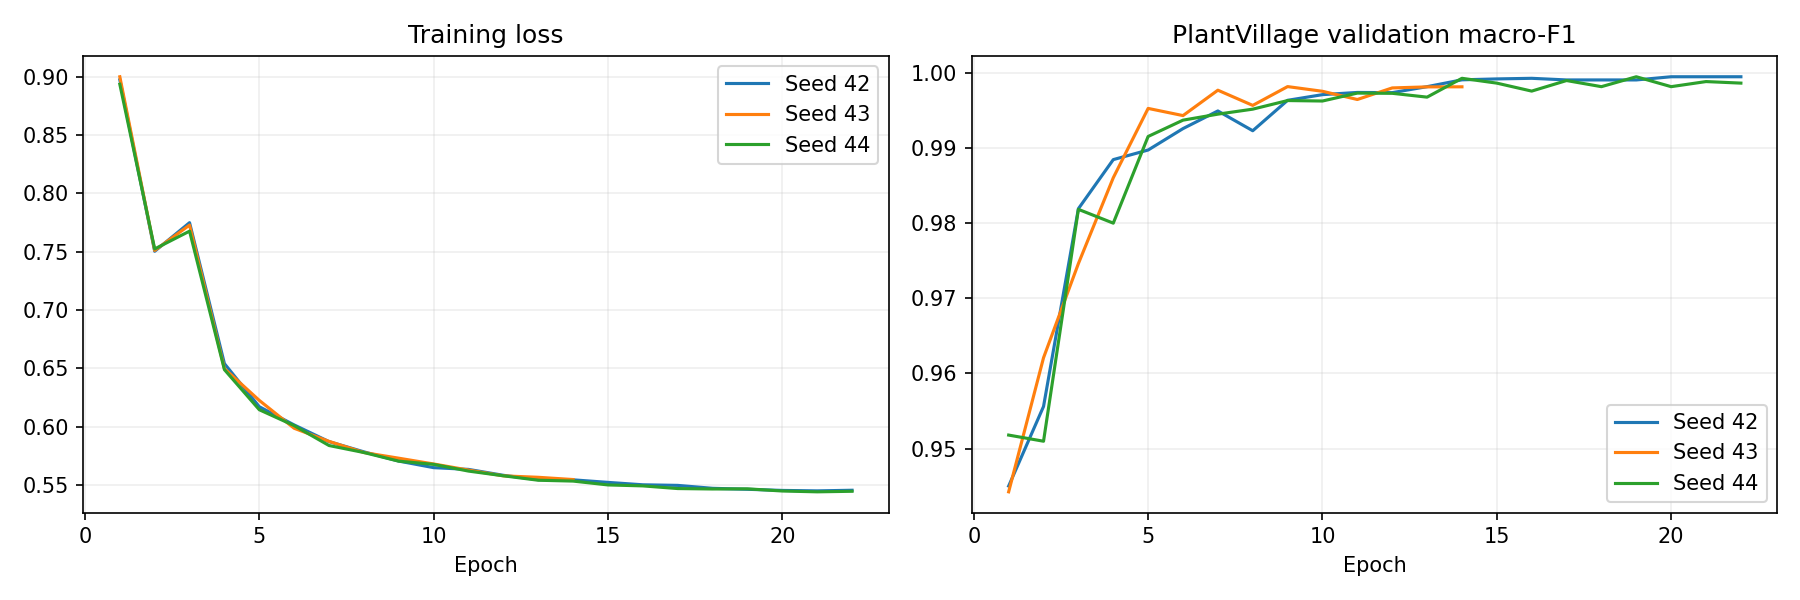

Across three prespecified training seeds, mean internal macro-F1 was 0.9975 and mean external macro-F1 was 0.2339. The mean absolute domain gap was 0.7636. These values describe the fixed shared dataset only; they do not establish field deployment reliability. Check the saved per-class reports and confusion matrices before attributing errors to a specific visual mechanism.

Seed standard deviations describe training variation. Per-run percentile bootstrap intervals use 1,000 resamples of the same external images and describe test-set sampling uncertainty. No three-model superiority claim is made by this notebook.


In [16]:
SUMMARY, results, statistics, gap = summarize(RUNS,WORK/'manifest.csv',WORK/'class_mapping.json')
display(results.round(4))
display(statistics.round(4))
display(gap.round(4))
display(DisplayImage(filename=str(SUMMARY/'training_curves.png')))
display(Markdown((SUMMARY/'measured_results_note.md').read_text()))


## 9. Per-class errors

I examined the per-class reports and row-normalised confusion matrices for all three seeds. The model transferred unevenly: mean external F1 was highest for tomato yellow leaf curl virus (about 0.527) and Septoria leaf spot (about 0.420), while tomato mosaic virus and leaf mould were particularly weak (about 0.024 and 0.028).

In seed 42, 56 of 91 tomato leaf-mould images and 37 of 63 healthy tomato images were predicted as tomato late blight. These mistakes help identify where transfer failed, but they do not show which visual feature caused the prediction. I did not implement Grad-CAM, paired comparisons with the other models or MATLAB reproduction for this notebook.


### Seed 42

,precision,recall,f1-score,support
Pepper_bell_bacterial_spot,0.4000,0.1972,0.2642,71.0000
Pepper_bell_healthy,0.2109,0.5082,0.2981,61.0000
Potato_early_blight,0.4808,0.2155,0.2976,116.0000
Potato_late_blight,0.4444,0.1143,0.1818,105.0000
Tomato_bacterial_spot,0.2800,0.0636,0.1037,110.0000
Tomato_early_blight,0.1634,0.4773,0.2435,88.0000
Tomato_late_blight,0.2117,0.6847,0.3234,111.0000
Tomato_leaf_mold,0.3333,0.0220,0.0412,91.0000
Tomato_septoria_leaf_spot,0.4160,0.3444,0.3768,151.0000
Tomato_yellow_leaf_curl_virus,0.6383,0.3947,0.4878,76.0000


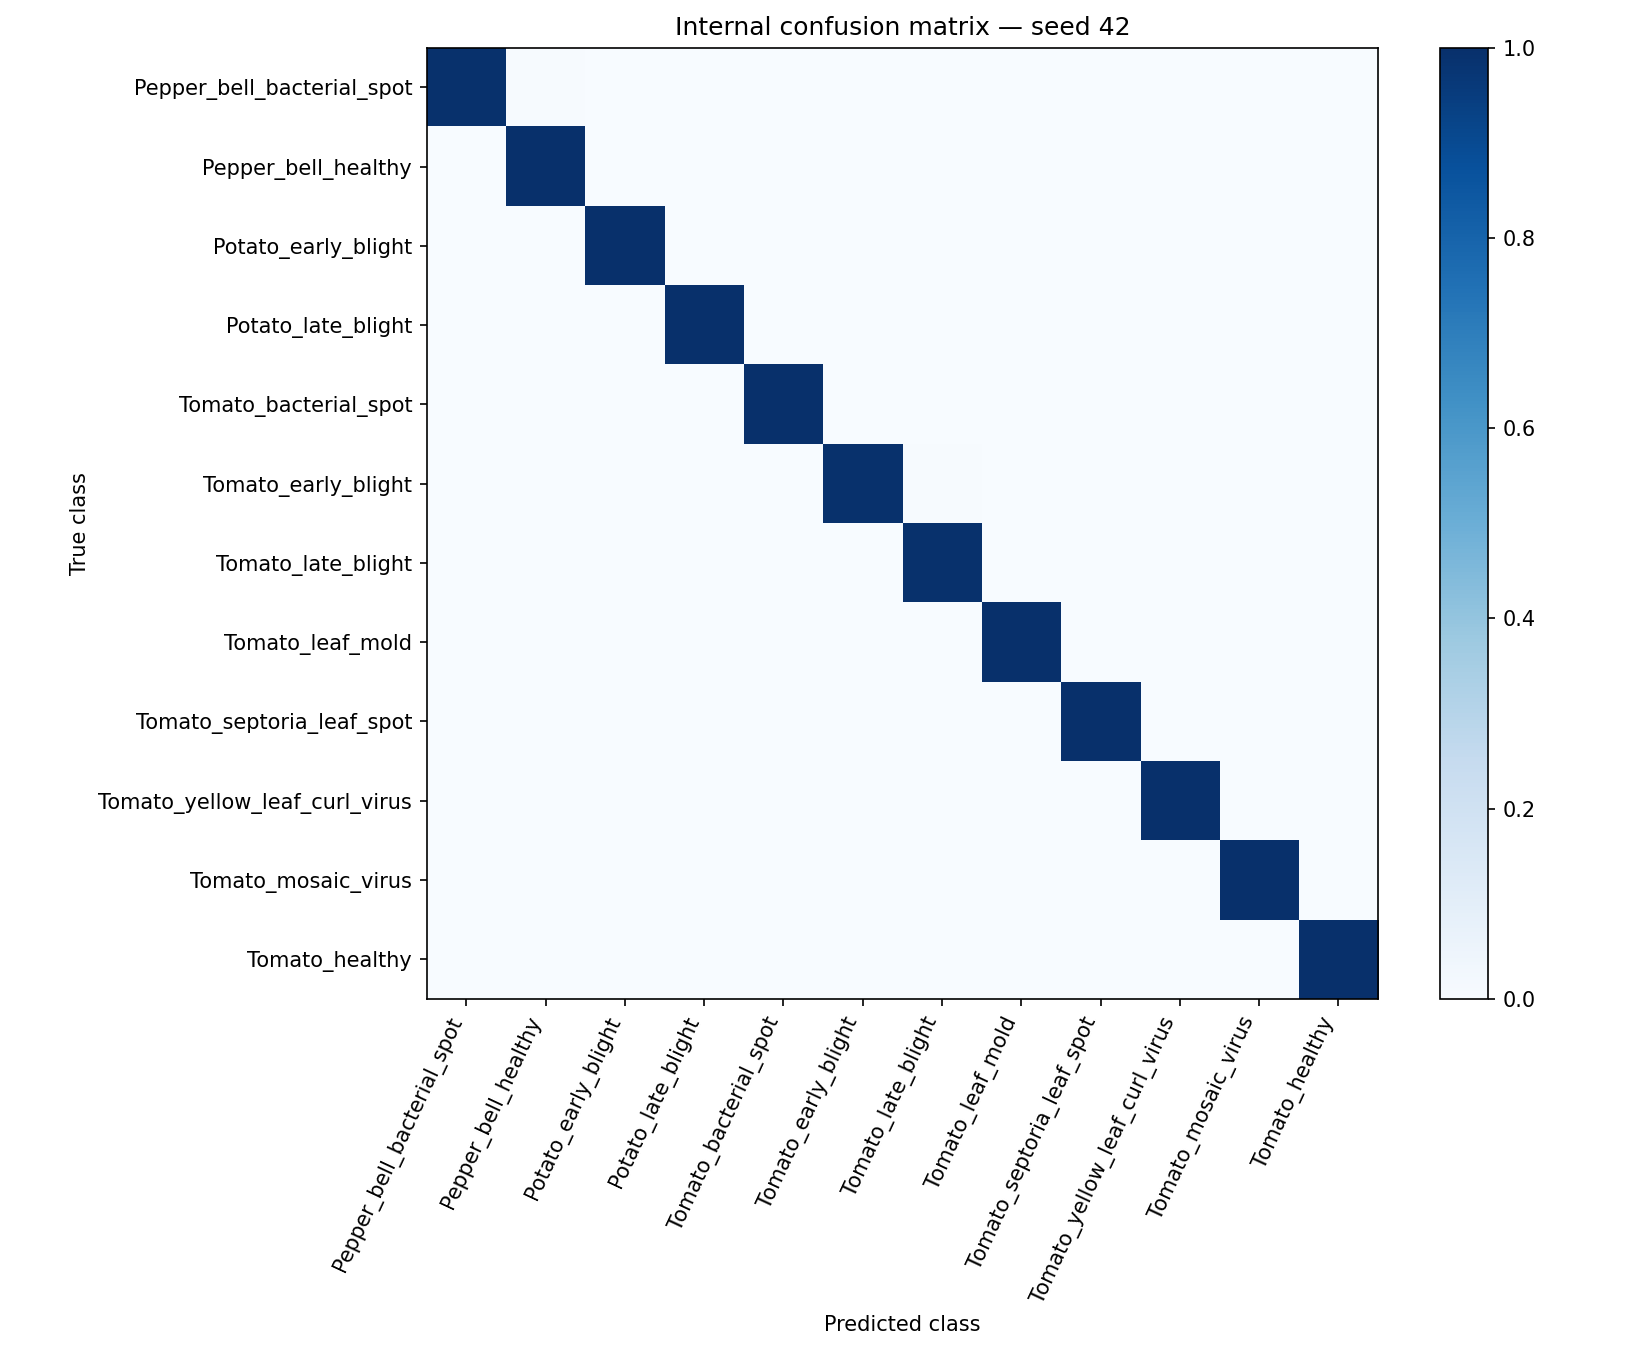

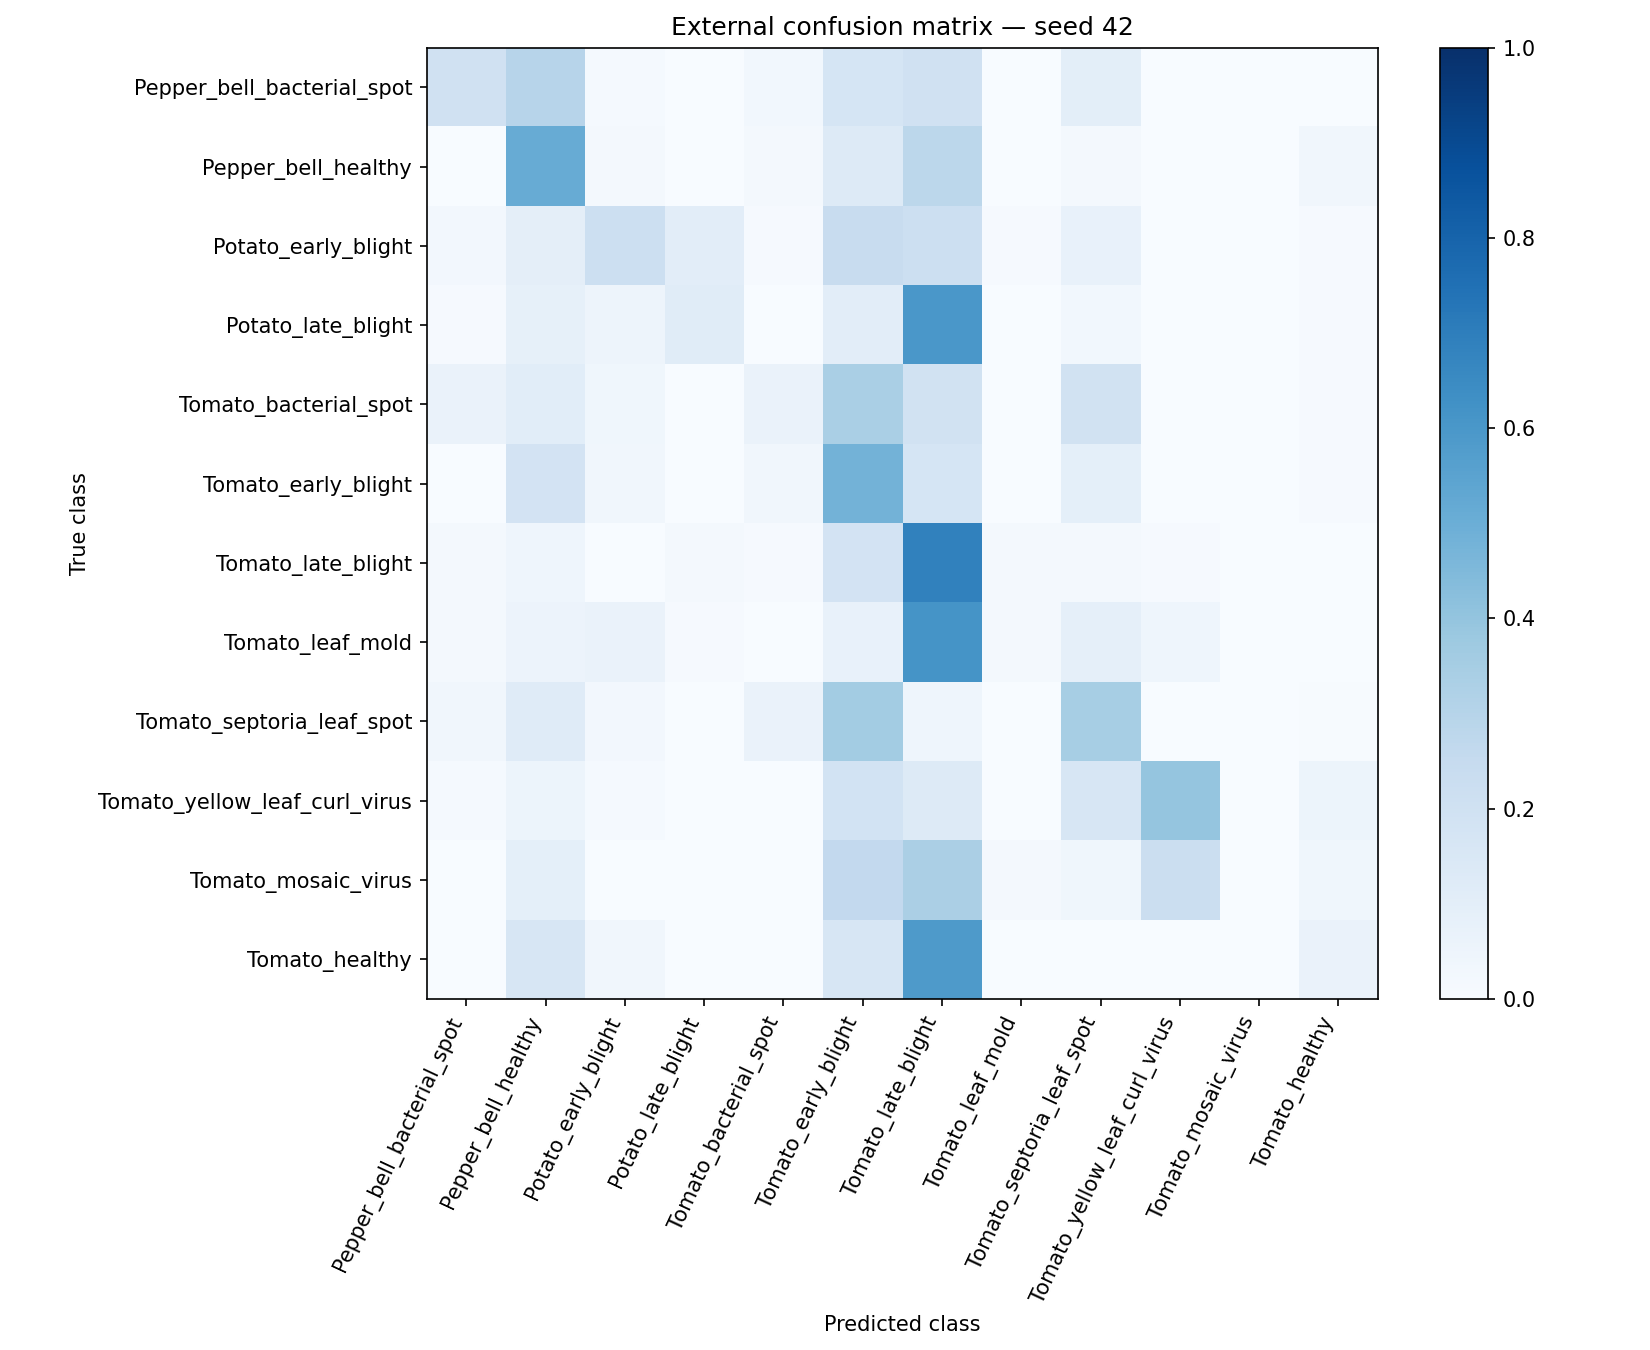

### Seed 43

,precision,recall,f1-score,support
Pepper_bell_bacterial_spot,0.3750,0.2535,0.3025,71.000
Pepper_bell_healthy,0.1466,0.7377,0.2446,61.000
Potato_early_blight,0.5714,0.1379,0.2222,116.000
Potato_late_blight,0.3684,0.0667,0.1129,105.000
Tomato_bacterial_spot,0.3200,0.0727,0.1185,110.000
Tomato_early_blight,0.1484,0.2614,0.1893,88.000
Tomato_late_blight,0.2771,0.6216,0.3833,111.000
Tomato_leaf_mold,0.1111,0.0110,0.0200,91.000
Tomato_septoria_leaf_spot,0.4408,0.4437,0.4422,151.000
Tomato_yellow_leaf_curl_virus,0.5769,0.5921,0.5844,76.000


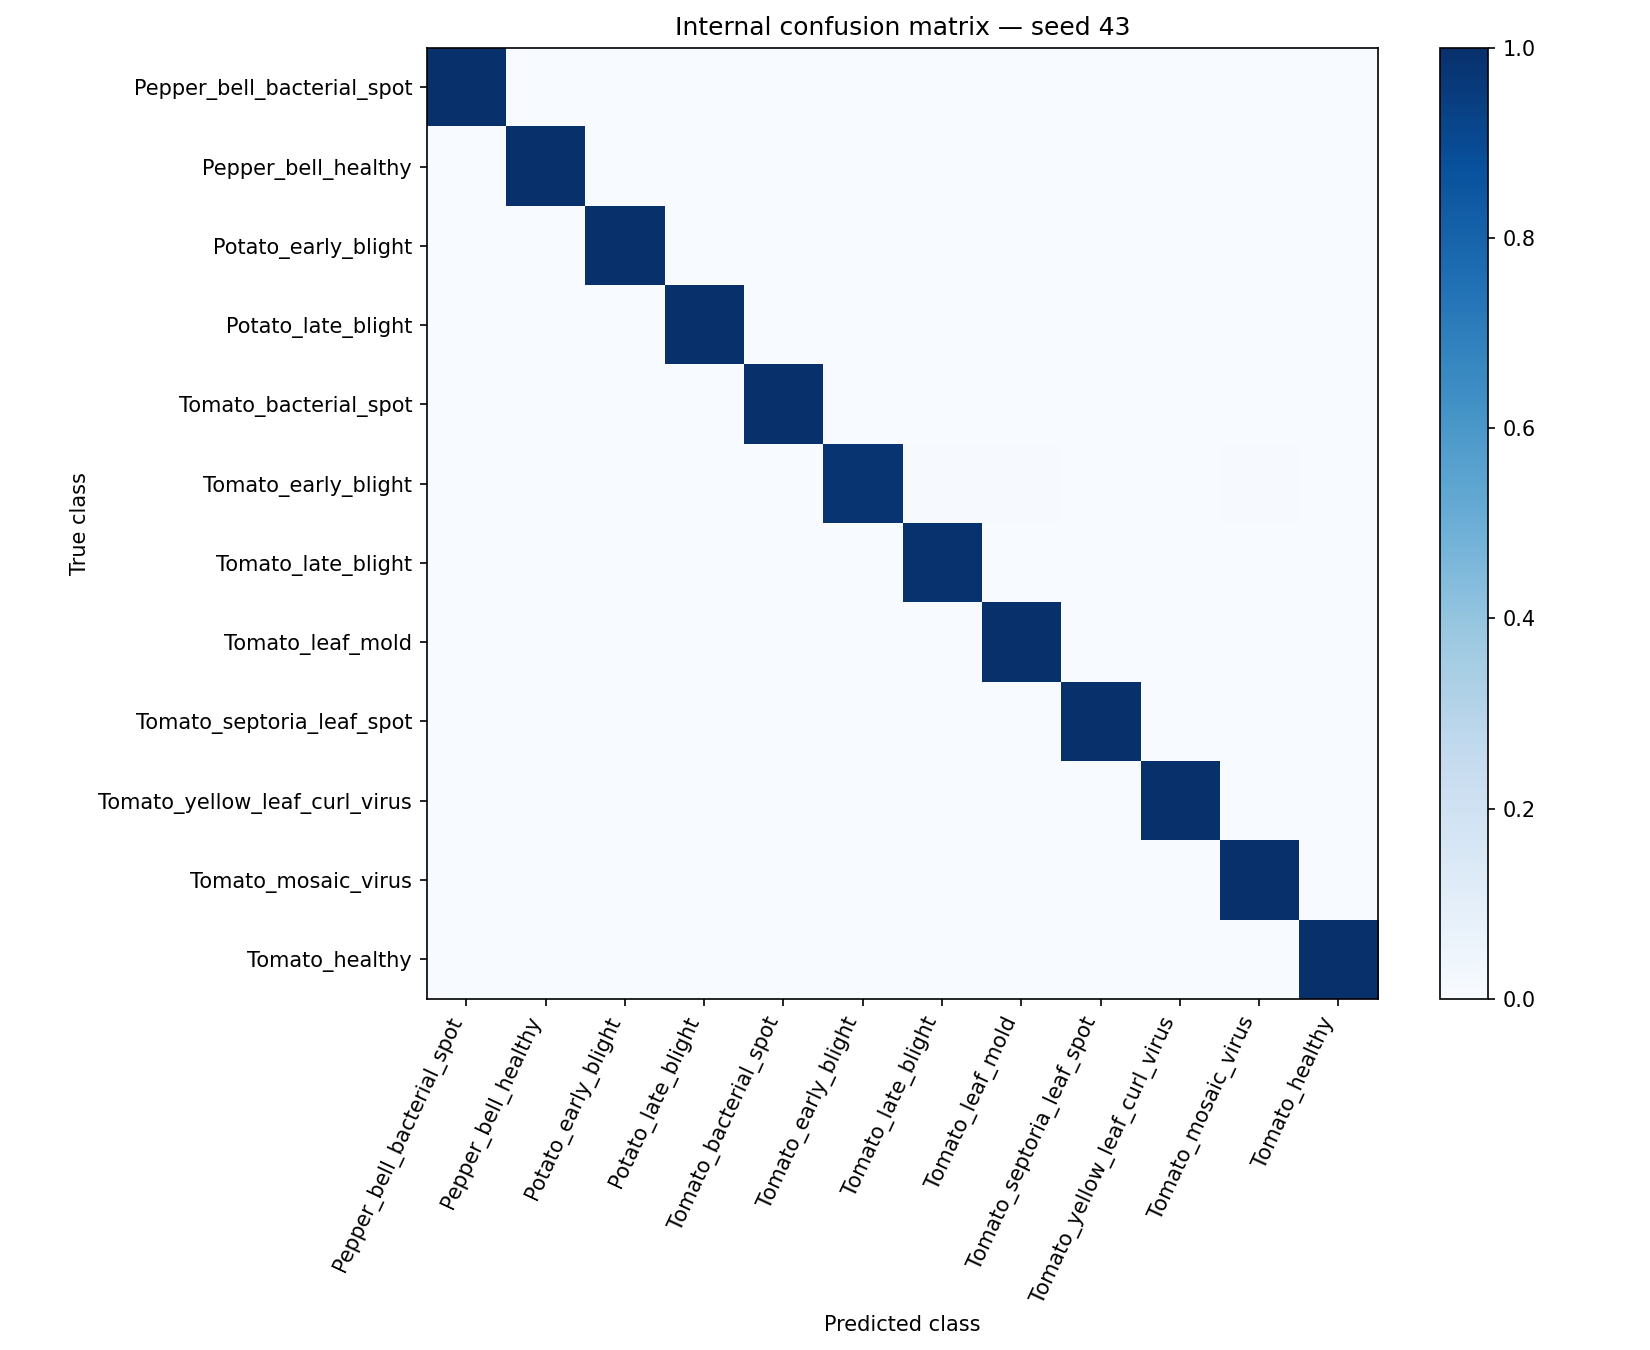

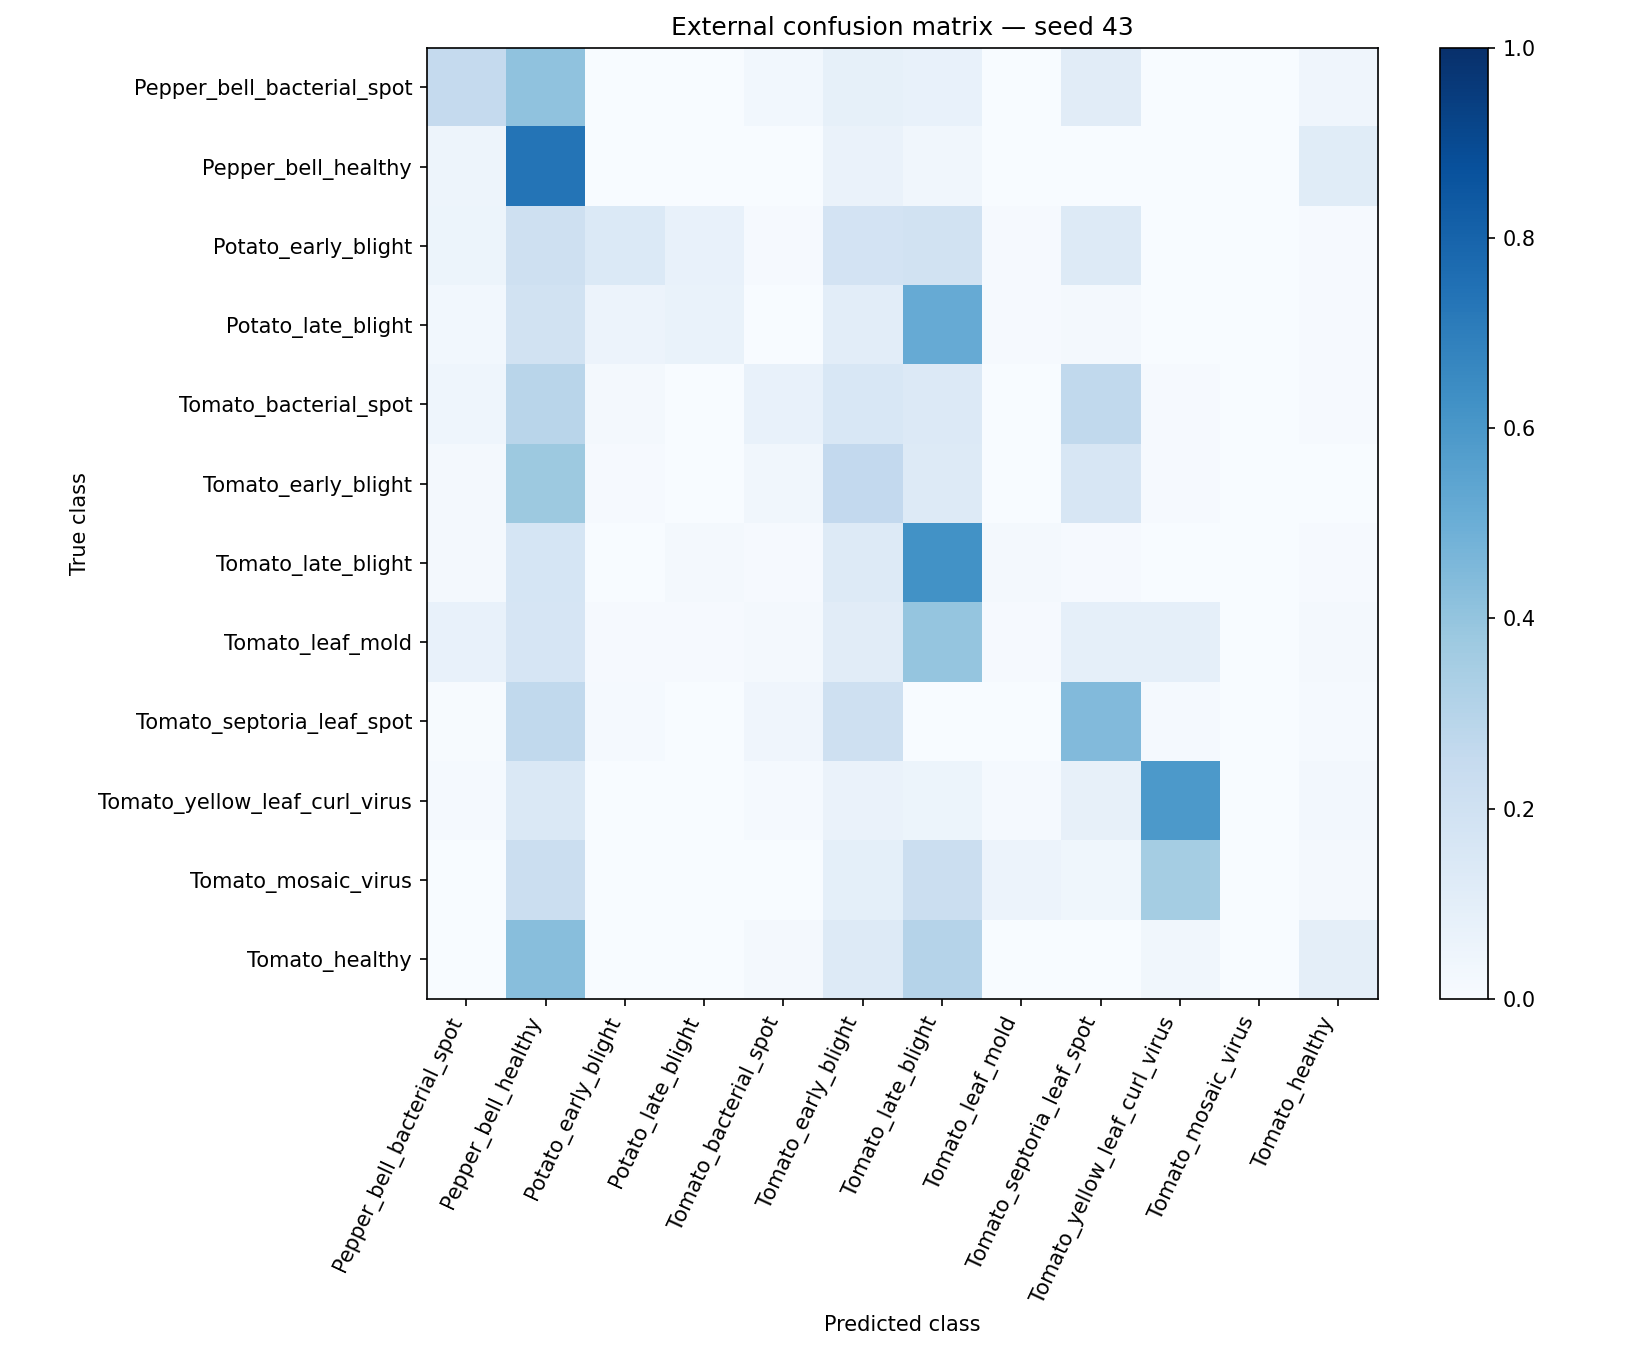

### Seed 44

,precision,recall,f1-score,support
Pepper_bell_bacterial_spot,0.5833,0.1972,0.2947,71.0000
Pepper_bell_healthy,0.1970,0.6557,0.3030,61.0000
Potato_early_blight,0.5088,0.2500,0.3353,116.0000
Potato_late_blight,0.3478,0.0762,0.1250,105.0000
Tomato_bacterial_spot,0.2963,0.0727,0.1168,110.0000
Tomato_early_blight,0.1893,0.3636,0.2490,88.0000
Tomato_late_blight,0.2201,0.7297,0.3382,111.0000
Tomato_leaf_mold,0.5000,0.0110,0.0215,91.0000
Tomato_septoria_leaf_spot,0.4379,0.4437,0.4408,151.0000
Tomato_yellow_leaf_curl_virus,0.6400,0.4211,0.5079,76.0000


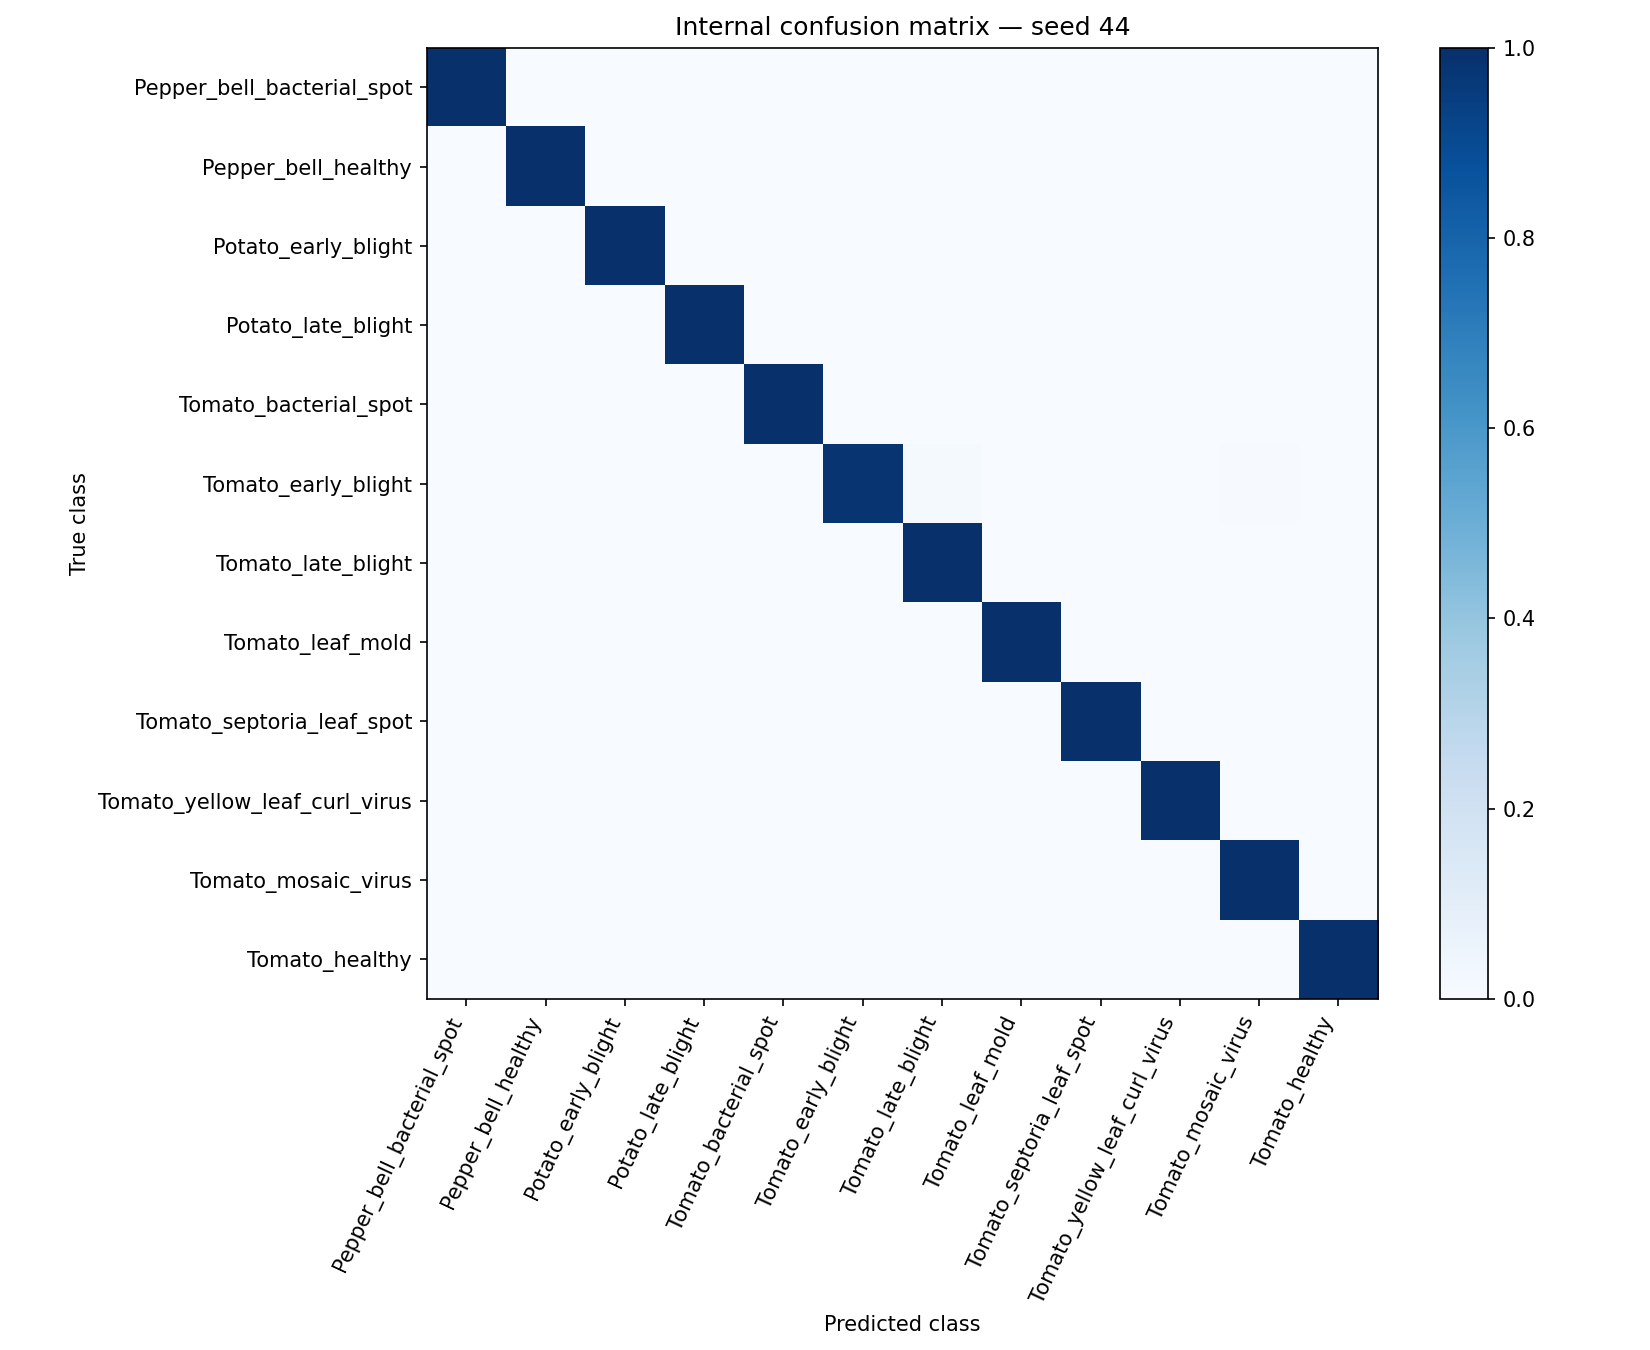

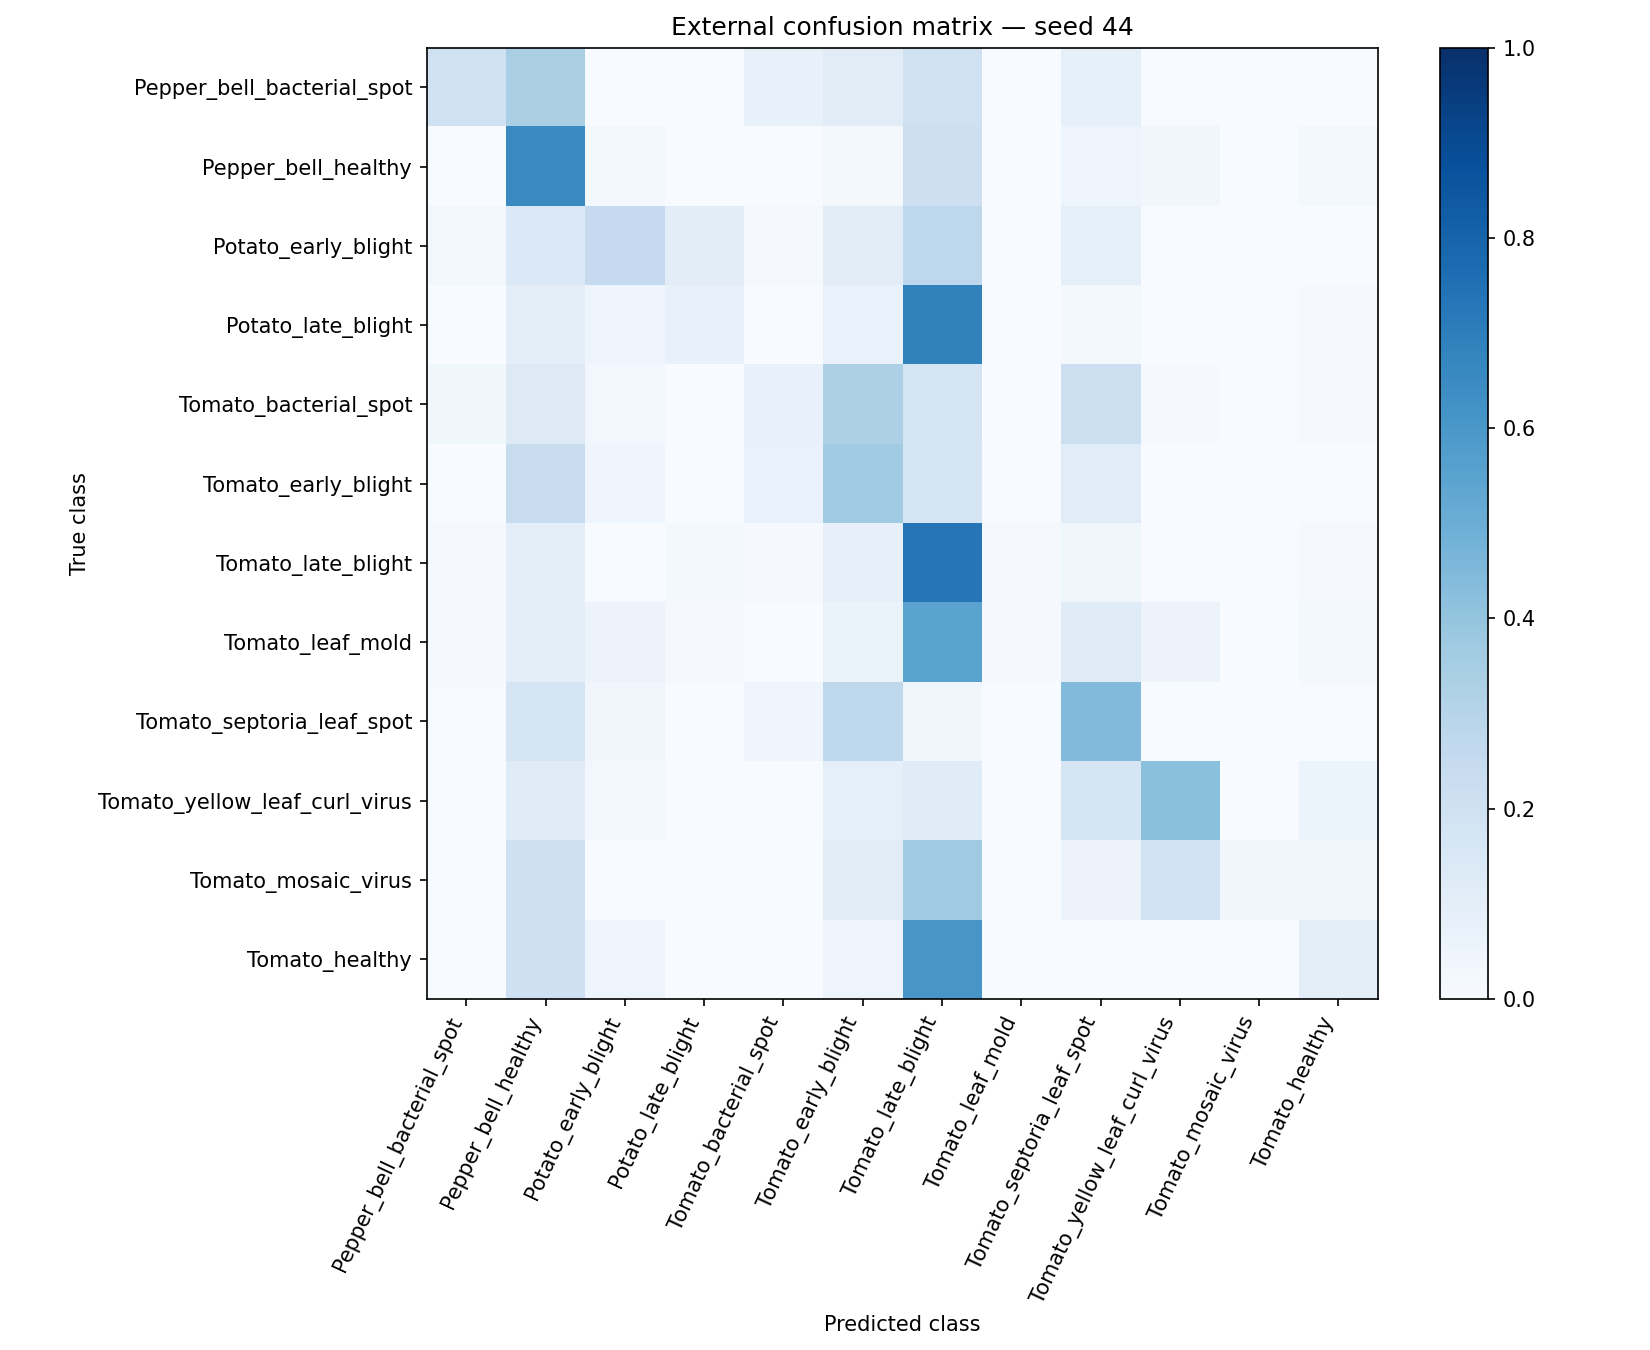

In [17]:
for seed in SEEDS:
    display(Markdown(f'### Seed {seed}'))
    display(pd.read_csv(SUMMARY/f'per_class_external_s{seed}.csv',index_col=0).round(4))
    display(DisplayImage(filename=str(SUMMARY/f'confusion_internal_s{seed}.png')))
    display(DisplayImage(filename=str(SUMMARY/f'confusion_external_s{seed}.png')))


## 10. Limitations and reproducibility

My main limitation is the controlled-to-field distribution difference. Cropped PlantDoc is one small, web-sourced dataset, so these results measure transfer to that source rather than general field reliability. Some classes have limited external support. High PlantVillage accuracy is therefore not enough to establish that the model is suitable for deployment.

I checked exact content hashes, but this does not rule out every near-duplicate or same-leaf relationship. My input transform also differs from Teddy's ResNet pipeline in resizing and normalisation. I have kept the sample identities, partitions and metric definitions fixed and reported the input-processing difference explicitly.

I saved the GPU model, software versions, configurations and manifest hashes. The script requests deterministic algorithms with warnings, but I do not assume bit-identical results across different CUDA or PyTorch versions. The original formal experiment uses batch 64 for every seed. Later single-seed augmentation trials were conducted after the external results were known and are not included in this summary.

I have reported YOLO results only. A final three-model ranking needs aligned predictions and paired analysis from all model owners. I do not infer statistical superiority from unmatched summary scores.

The final cell packages my source code, configurations, models, predictions, audits, statistics and figures. I have retained the measured outputs in this notebook as part of the experiment record.


In [18]:
required=['notebook_environment.json','frozen_before_external.json','pv_extraction_audit.json','external_audit.json','summary/results_per_seed.csv']
assert all((RUNS/f).exists() for f in required)
for seed in SEEDS:
    assert (RUNS/f'eval_s{seed}/predictions_external.csv').exists()
    assert (RUNS/f'eval_s{seed}/predictions_internal.csv').exists()
bundle=shutil.make_archive(str(RUNS)+'_submission','zip',root_dir=RUNS)
print('Experiment complete:',RUNS)
print('Evidence archive:',bundle)
print('Save/download this notebook with its measured outputs before submission.')


Experiment complete: /content/drive/MyDrive/42177/runs/yolo11s_b64_20261018_081158_1afe1516
Evidence archive: /content/drive/MyDrive/42177/runs/yolo11s_b64_20261018_081158_1afe1516_submission.zip
Save/download this notebook with its measured outputs before submission.


## Conclusion

I completed three formal runs of YOLO11s-cls on the shared twelve-class task. All runs used a Tesla T4, batch 64 and float32 precision. Seeds 42, 43 and 44 completed twenty-two, fourteen and twenty-two total epochs, respectively. I selected each checkpoint using PlantVillage validation macro-F1 only.

| Test set | Accuracy, mean ± sample SD | Macro-F1, mean ± sample SD |
|---|---:|---:|
| PlantVillage internal | 0.99796 ± 0.00058 | 0.99754 ± 0.00096 |
| Cropped PlantDoc external | 0.27955 ± 0.01147 | 0.23393 ± 0.01042 |

The mean macro-F1 gap was **0.76361**, and the external result did not reach our provisional target of 0.40. My conclusion is that the model learned the controlled-image task well but had limited cross-dataset generalisation. The result does not establish field readiness or superiority over another architecture.

The post-run checks reproduced the saved accuracy and macro-F1, all six confusion matrices and all three 1,000-resample external confidence intervals. They also confirmed that the predictions matched the team's image IDs and labels, and that the evaluated checkpoints matched the pre-external freeze record. The recorded audits verified all 17,392 PlantVillage and 1,097 external image hashes.

I integrated the filename repair into the embedded source so that this formal version no longer needs the temporary repair cell. The original measured outputs are retained. Later single-seed trials remain separate from this three-seed conclusion.


## References and implementation provenance

I used the following sources for the model, datasets and shared experiment files:

- Ultralytics. (n.d.). *Ultralytics YOLO11*. https://docs.ultralytics.com/models/yolo11/
- Ultralytics. (n.d.). *Image classification*. https://docs.ultralytics.com/tasks/classify/
- Hughes, D. P., & Salathé, M. (2015). *An open access repository of images on plant health to enable the development of mobile disease diagnostics* [Preprint]. arXiv. https://arxiv.org/abs/1511.08060
- Singh, D., Jain, N., Jain, P., Kayal, P., Kumawat, S., & Batra, N. (2020). PlantDoc: A dataset for visual plant disease detection. In *Proceedings of the 7th ACM IKDD CoDS and 25th COMAD* (pp. 249–253). https://doi.org/10.1145/3371158.3371196
- PlantVillage data copy: https://www.kaggle.com/datasets/emmarex/plantdisease
- Cropped PlantDoc repository: https://github.com/pratikkayal/PlantDoc-Dataset
- Team manifest, class mapping and prediction format: Teddy Ryu's https://github.com/TeddybearAi/42177-A2-Project-Implementation , commit `62aa3152d993bffcdf87b4ace9a0e9233705b8e7`.

**Use of AI:** I used ChatGPT/Codex to assist with code drafting, debugging, result checking and notebook organisation. I remain responsible for reviewing the outputs, interpreting the results and meeting the course's disclosure requirements.
